# Step 1 - Import The Data Set

In [1]:
import pandas as pd
diabetes_path = "/content/drive/MyDrive/diabetes.csv"

# Step 2 - Give Column Names

In [2]:
diabetes_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

# Step 3 - Load the Diabertes Data set

In [3]:
df = pd.read_csv(diabetes_path, names=diabetes_columns, header=0)

# Step 4 - Display the first five row


In [4]:
df.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0


# step 5 - Display the Last Five Row


In [5]:
df.tail(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
762,10,101,76,48,180,32.9,0.171,63,0
763,2,122,70,27,0,36.8,0.340,27,0
764,5,121,72,23,112,26.2,0.245,30,0
765,1,126,60,0,0,30.1,0.349,47,1
766,1,93,70,31,0,30.4,0.315,23,0


# Step 6 - Display Rows and Column


In [6]:
df.shape

(767, 9)

# Step 7 - Display column names


In [7]:
df.columns.tolist()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

# Step 8 - Display The Data types


In [8]:
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


# Step 9 - Display the Info


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               767 non-null    int64  
 1   Glucose                   767 non-null    int64  
 2   BloodPressure             767 non-null    int64  
 3   SkinThickness             767 non-null    int64  
 4   Insulin                   767 non-null    int64  
 5   BMI                       767 non-null    float64
 6   DiabetesPedigreeFunction  767 non-null    float64
 7   Age                       767 non-null    int64  
 8   Outcome                   767 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


# Step 10 - Display the Discription


In [10]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000
mean,3.842243,120.859192,69.101695,20.517601,79.903520,31.990482,0.471674,33.219035,0.348110
std,3.370877,31.978468,19.368155,15.954059,115.283105,7.889091,0.331497,11.752296,0.476682
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243500,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,32.000000,32.000000,0.371000,29.000000,0.000000
75%,6.000000,140.000000,80.000000,32.000000,127.500000,36.600000,0.625000,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


# Step 11 - Identify The Input and Target Variable


In [11]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]
print("Input features:", X.columns.tolist())
print("Target variable:", y.name)

Input features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Target variable: Outcome


# Step 12 - Check the Dublicate and Remove It


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

# Step 13 -


In [14]:
import numpy as np
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

# Step 14 - Check the missing value


In [15]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,373
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


# Step 15 - Plot Numerical Distribution


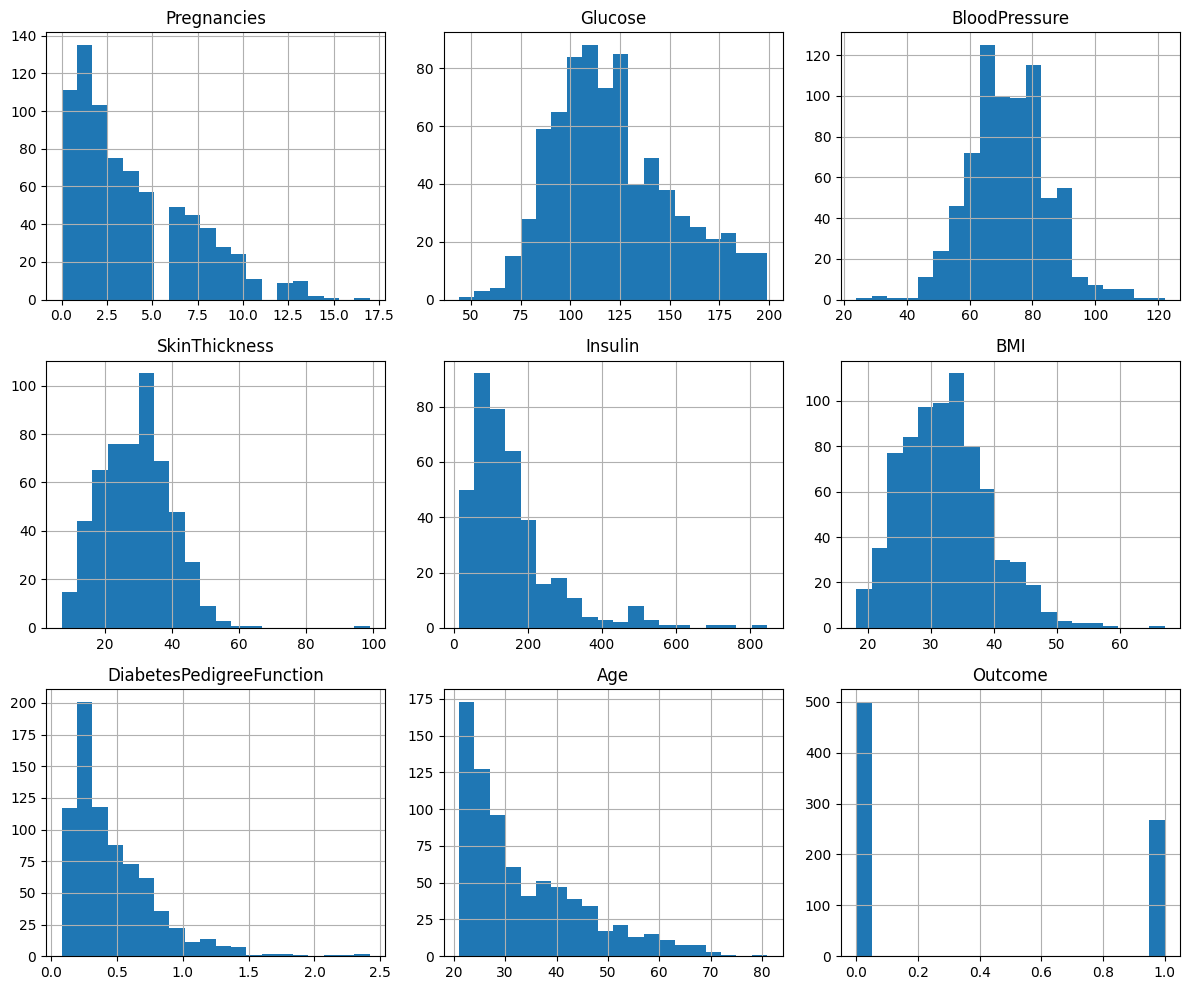

In [16]:
import matplotlib.pyplot as plt

df.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

# Step 16 - Calculate Skewness


In [17]:
X.skew()

,0
Pregnancies,0.903976
Glucose,0.176412
BloodPressure,-1.841911
SkinThickness,0.112058
Insulin,2.270630
BMI,-0.427950
DiabetesPedigreeFunction,1.921190
Age,1.135165


# Step 17 - Decide Mean or Median


In [18]:
for column in X:
  skew_value = df[column].skew()
  if -0.5 <= skew_value <= 0.5:
    print(column,"-> Use mean")
  else:
    print(column,"-> Use median")

Pregnancies -> Use median
Glucose -> Use median
BloodPressure -> Use mean
SkinThickness -> Use median
Insulin -> Use median
BMI -> Use median
DiabetesPedigreeFunction -> Use median
Age -> Use median


# Step 18 - Fill the Missing Values Using fillna


In [19]:
df["Pregnancies"] = df["Pregnancies"].fillna(df["Pregnancies"].median())
df["Glucose"] = df["Glucose"].fillna(df["Glucose"].mean())
df["BloodPressure"] = df["BloodPressure"].fillna(df["BloodPressure"].mean())
df["SkinThickness"] = df["SkinThickness"].fillna(df["SkinThickness"].median())
df["Insulin"] = df["Insulin"].fillna(df["Insulin"].median())
df["BMI"] = df["BMI"].fillna(df["BMI"].median())
df["DiabetesPedigreeFunction"] = df["DiabetesPedigreeFunction"].fillna(df["DiabetesPedigreeFunction"].median())
df["Age"] = df["Age"].fillna(df["Age"].median())

# Step 19 - Verify missing values

In [20]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


# Step 20 - Check Class Distribution


In [21]:
df["Outcome"].value_counts()

,count
Outcome,
0,500
1,267


# Step 21 - Plot Class Distribution


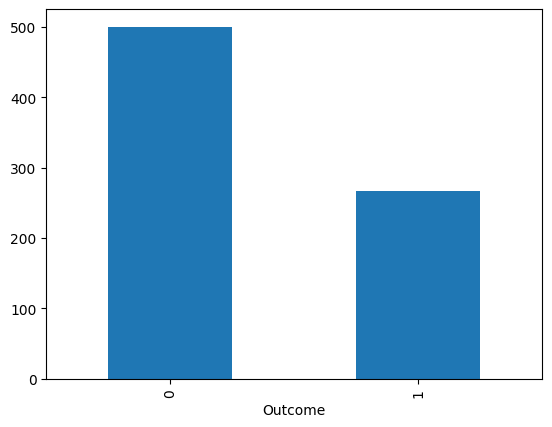

In [22]:
df["Outcome"].value_counts().plot(kind="bar")
plt.show()

# Step 22 - Seperate Input and Target


In [23]:
X = df.drop(columns=["Outcome"],axis=1)
y = df["Outcome"]
print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (767, 8)
Target variable: (767,)


# Step 23 - Data spliting

In [24]:
from sklearn.model_selection import train_test_split
X_train_diabetes, X_test_diabetes, y_train_diabetes, y_test_diabetes = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train_diabetes:", X_train_diabetes.shape[0])
print("X_test_diabetes:", X_test_diabetes.shape[0])


X_train_diabetes: 613
X_test_diabetes: 154


# Step 24 - Imoprt and Create Decition Tree Model

In [25]:
from sklearn.tree import DecisionTreeClassifier
decision_tree_model = DecisionTreeClassifier(
    max_depth=4,
    class_weight="balanced",
    random_state=42
    )

# Step 25 - Train the Model

In [26]:
decision_tree_model.fit(
    X_train_diabetes,
    y_train_diabetes
    )
print("Decision Tree Model Trained successfully")

Decision Tree Model Trained successfully


# Step 26 - Predict Test Data

In [27]:
diabetes_prediction = decision_tree_model.predict(
    X_test_diabetes
    )

# Step 27 -
## **Matrix for classification**
* Accuracy

* Precision

* Recall

* Confution Matrix

* F1-Score

In [28]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score
print("Accuracy:", accuracy_score(y_test_diabetes, diabetes_prediction))
print("Precision:", precision_score(y_test_diabetes, diabetes_prediction))
print("Recall:", recall_score(y_test_diabetes, diabetes_prediction))
print("Confusion Matrix:\n", confusion_matrix(y_test_diabetes, diabetes_prediction))
print("F1-Score:", f1_score(y_test_diabetes, diabetes_prediction))

Accuracy: 0.7142857142857143
Precision: 0.5694444444444444
Recall: 0.7592592592592593
Confusion Matrix:
 [[69 31]
 [13 41]]
F1-Score: 0.6507936507936508


# Step 28 - Plot the Decision Tree

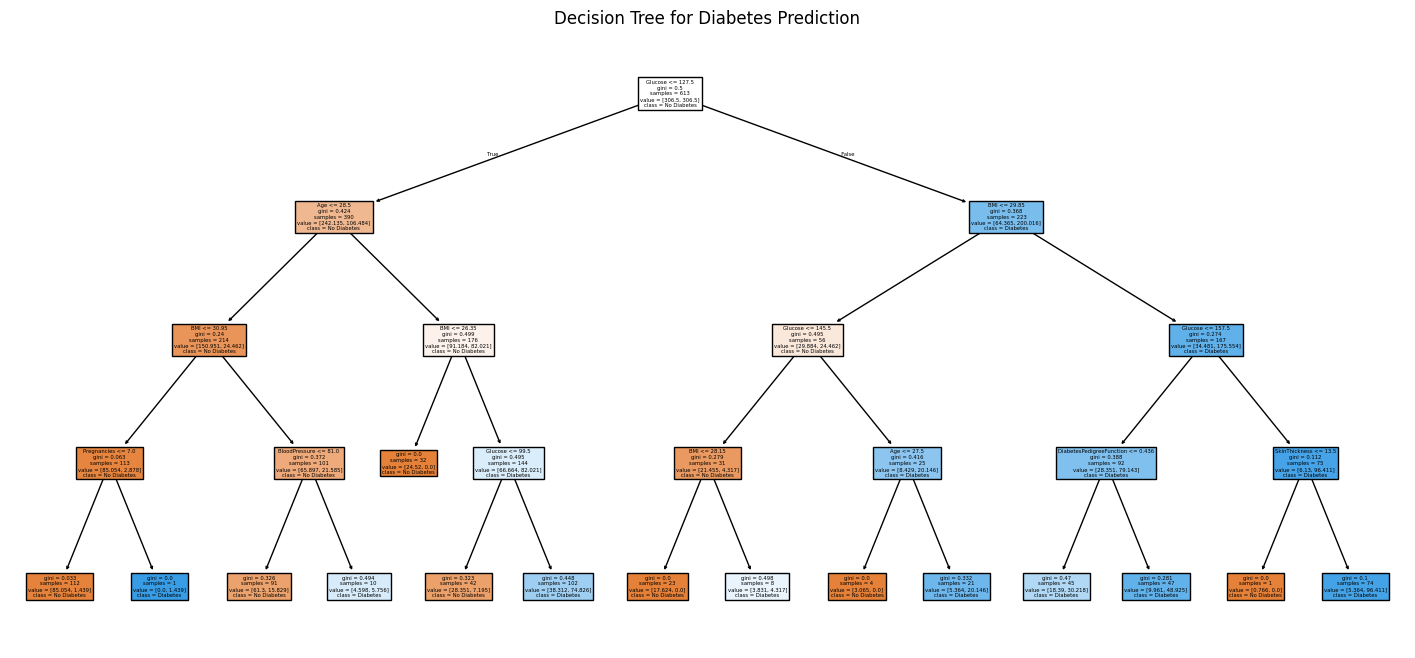

In [29]:
from sklearn.tree import plot_tree
plt.figure(figsize=(18, 8))
plot_tree(
    decision_tree_model,
    filled=True,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"]
)
plt.title("Decision Tree for Diabetes Prediction")
plt.show()


# Step 29 -

In [30]:
new_patient = pd.DataFrame({
    "Pregnancies": [2],
    "Glucose": [145],
    "BloodPressure": [82],
    "SkinThickness": [30],
    "Insulin": [125],
    "BMI": [32.5],
    "DiabetesPedigreeFunction": [0.45],
    "Age": [35]
    })

In [31]:
patient_prediction = decision_tree_model.predict(new_patient)[0]
print("Patient Prediction:", patient_prediction)
if patient_prediction == 1:
    print("Result: Diabetes")
else:
    print("Result: No Diabetes")

Patient Prediction: 1
Result: Diabetes
